In [1]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.model_selection import cross_validate
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

In [2]:
df = sklearn.datasets.fetch_openml(name='credit-g', version=1)
X = df.data
y = df.target

In [3]:
X.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


In [4]:
y.value_counts()

class
good    700
bad     300
Name: count, dtype: int64

Excluindo a variável target.

7 variáveis numéricas.

13 variáveis categóricas.

Arvores de decisão não exigem normalização dos dados de entrada, ela trabalha com dados categóricos, como dados numéricos. porém por padrão o scikit-learn exige variáveis numéricas.

Devido ao desbalanceamento do dataset é interessante se avaliar cuidadosamente todas as métricas e não somente a acurácia, pois um modelo poderia classificar corretamente todos os bons pagadores e metade dos maus pagadores e ainda ter 85% de acurácia, a precisão estaria em 50% para maus pagadores resultando em metade do maus pagadores tendo acesso crédito.

In [5]:
X_encoded = pd.get_dummies(X, dtype=int)
X_encoded

,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents,checking_status_0<=X<200,checking_status_<0,checking_status_>=200,...,housing_own,housing_rent,job_high qualif/self emp/mgmt,job_unemp/unskilled non res,job_unskilled resident,job_skilled,own_telephone_none,own_telephone_yes,foreign_worker_no,foreign_worker_yes
0,6,1169,4,4,67,2,1,0,1,0,...,1,0,0,0,0,1,0,1,0,1
1,48,5951,2,2,22,1,1,1,0,0,...,1,0,0,0,0,1,1,0,0,1
2,12,2096,2,3,49,1,2,0,0,0,...,1,0,0,0,1,0,1,0,0,1
3,42,7882,2,4,45,1,2,0,1,0,...,0,0,0,0,0,1,1,0,0,1
4,24,4870,3,4,53,2,2,0,1,0,...,0,0,0,0,0,1,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,12,1736,3,4,31,1,1,0,0,0,...,1,0,0,0,1,0,1,0,0,1
996,30,3857,4,4,40,1,1,0,1,0,...,1,0,1,0,0,0,0,1,0,1
997,12,804,4,4,38,1,1,0,0,0,...,1,0,0,0,0,1,1,0,0,1
998,45,1845,4,4,23,1,1,0,1,0,...,0,0,0,0,0,1,0,1,0,1


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)
print(f"Tamanho do conjunto do dataset:{X.shape[0]} amostras")
print(f"Quantidade de amostras de conjunto de treino: {X_train.shape[0]} amostras")
print(f"Quantidade de amostras de conjunto de treino: {X_test.shape[0]} amostras")

Tamanho do conjunto do dataset:1000 amostras
Quantidade de amostras de conjunto de treino: 800 amostras
Quantidade de amostras de conjunto de treino: 200 amostras


In [7]:
profundidade = [2, 3, 5, 7, 10, None]
criterios = ['gini', 'entropy']

resultados = []

for criterio in criterios:
    for pf in profundidade:

        model = tree.DecisionTreeClassifier(
            criterion=criterio,
            max_depth=pf,
            random_state=42
        )

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=5,
            return_train_score=True
        )

        resultados.append({
            'criterio': criterio,
            'profundidade': pf,
            'treino': np.mean(scores['train_score']),
            'validacao': np.mean(scores['test_score'])
        })

resultados = pd.DataFrame(resultados)

resultados


,criterio,profundidade,treino,validacao
0,gini,2.0,0.722500,0.70625
1,gini,3.0,0.744688,0.69250
2,gini,5.0,0.805937,0.69500
3,gini,7.0,0.863438,0.69500
4,gini,10.0,0.938125,0.69625
5,gini,NaN,1.000000,0.68125
6,entropy,2.0,0.712813,0.70625
7,entropy,3.0,0.732187,0.70125
8,entropy,5.0,0.793438,0.71000
9,entropy,7.0,0.842812,0.69250


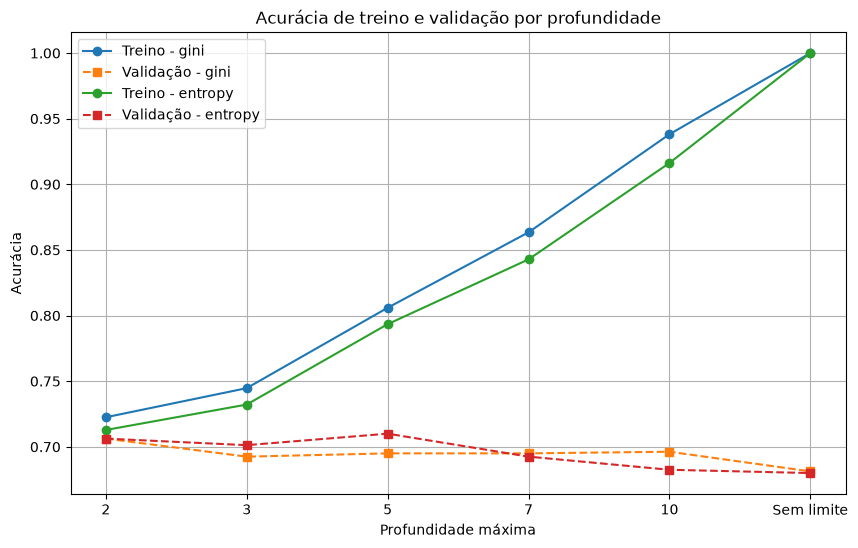

In [8]:
plt.figure(figsize=(10, 6))

for criterio in criterios:

    dados = resultados[
        resultados['criterio'] == criterio
    ]

    plt.plot(
        range(len(profundidade)),
        dados['treino'],
        marker='o',
        label=f'Treino - {criterio}'
    )

    plt.plot(
        range(len(profundidade)),
        dados['validacao'],
        marker='s',
        linestyle='--',
        label=f'Validação - {criterio}'
    )

plt.xticks(
    range(len(profundidade)),
    ['2', '3', '5', '7', '10', 'Sem limite']
)

plt.xlabel('Profundidade máxima')
plt.ylabel('Acurácia')
plt.title('Acurácia de treino e validação por profundidade')
plt.legend()
plt.grid()
plt.show()

In [9]:
# %%
melhor = resultados.loc[
    resultados['validacao'].idxmax()
]

print("Melhor resultado:")
print(melhor)

melhor_criterio = melhor['criterio']
melhor_profundidade = int(melhor['profundidade'])

modelo_final = tree.DecisionTreeClassifier(
    criterion=melhor_criterio,
    max_depth=melhor_profundidade,
    random_state=42
)

modelo_final.fit(X_train, y_train)

Melhor resultado:
criterio         entropy
profundidade         5.0
treino          0.793438
validacao           0.71
Name: 8, dtype: object


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

A profundidade da árvore controla sua complexidade. Árvores com
profundidade muito baixa podem apresentar underfitting, pois não
conseguem aprender adequadamente os padrões dos dados. Já árvores
muito profundas podem apresentar overfitting, memorizando características
do conjunto de treinamento e prejudicando a generalização.

O melhor modelo foi escolhido considerando a maior acurácia média
obtida na validação cruzada.

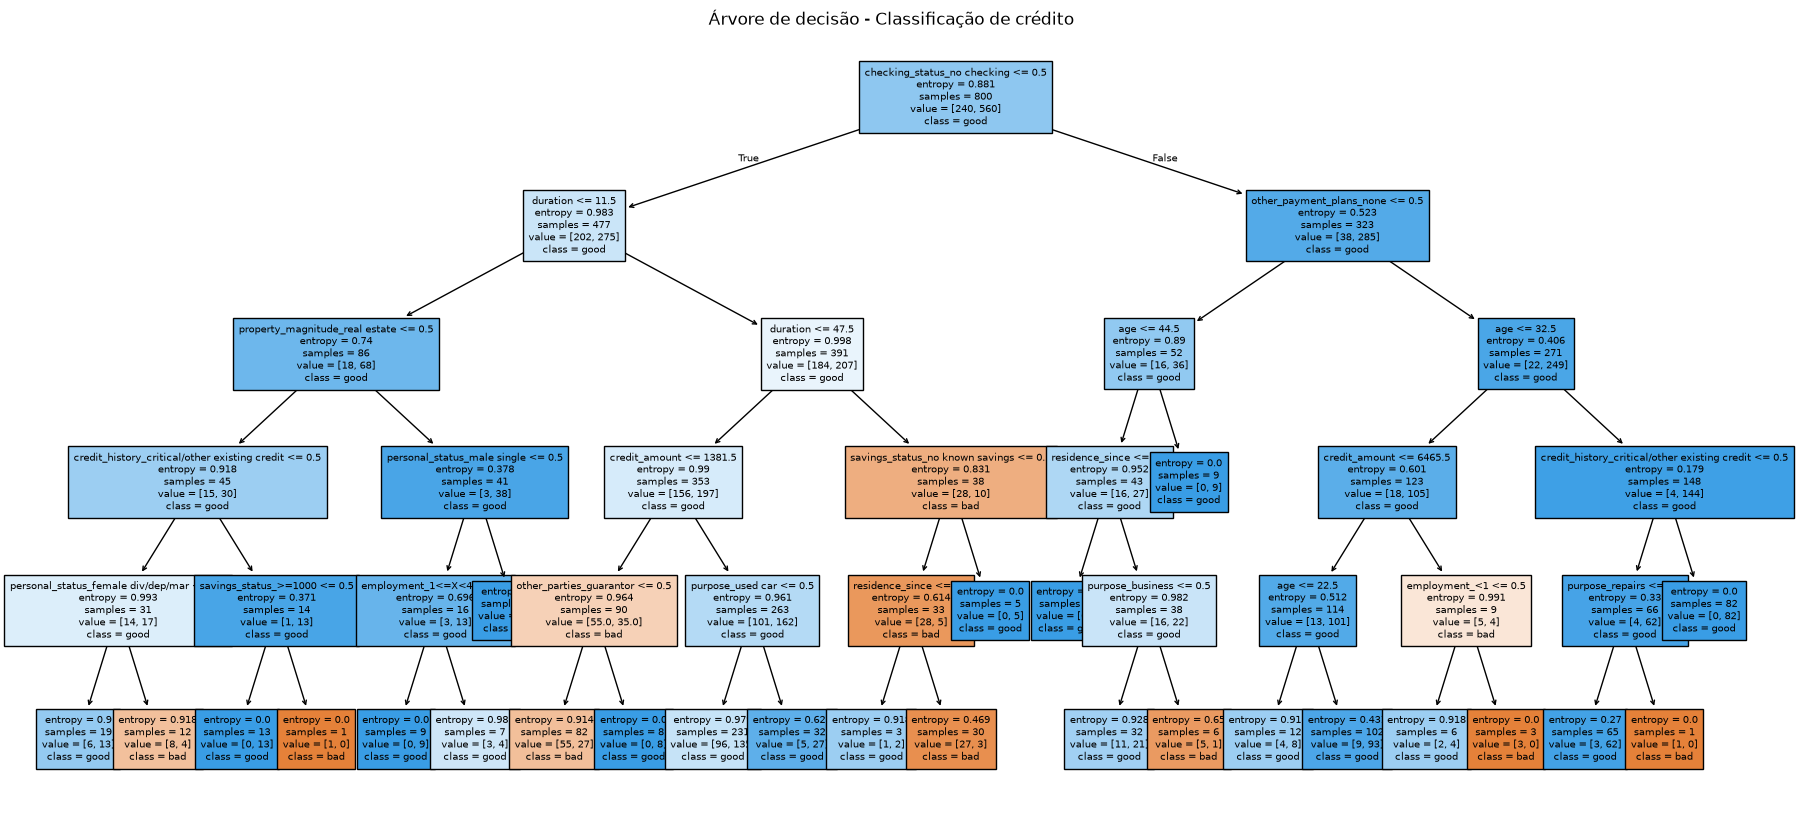

In [10]:
plt.figure(figsize=(22, 10))
tree.plot_tree(
    modelo_final,
    feature_names=X_encoded.columns,
    class_names=modelo_final.classes_,
    filled=True,
    fontsize=7
)
plt.title('Árvore de decisão - Classificação de crédito')
plt.show()

In [11]:
importancias = pd.DataFrame({
    'Atributo': X_encoded.columns,
    'Importancia': modelo_final.feature_importances_
})

importancias = importancias.sort_values(
    by='Importancia',
    ascending=False
)

print(importancias)

print("\nTrês atributos mais importantes:")
print(importancias.head(3))

                       Atributo  Importancia
10  checking_status_no checking     0.305512
0                      duration     0.109360
4                           age     0.083919
1                 credit_amount     0.075679
48     other_payment_plans_none     0.056109
..                          ...          ...
56                  job_skilled     0.000000
57           own_telephone_none     0.000000
58            own_telephone_yes     0.000000
59            foreign_worker_no     0.000000
60           foreign_worker_yes     0.000000

[61 rows x 2 columns]

Três atributos mais importantes:
                       Atributo  Importancia
10  checking_status_no checking     0.305512
0                      duration     0.109360
4                           age     0.083919


Os três atributos com maior importância foram:
- checking_status_no checking: importância de aproximadamente 30,55%;
- duration: importância de aproximadamente 10,94%;
- age: importância de aproximadamente 8,39%.
O atributo relacionado à situação da conta corrente (checking_status_no checking) apresentou a maior importância, indicando que essa informação teve participação expressiva nas divisões da árvore.

Em seguida, destacaram-se a duração do crédito (duration) e a idade do solicitante (age).

In [12]:
arvore = modelo_final.tree_

folhas = []

def percorrer_arvore(no, caminho):

    esquerda = arvore.children_left[no]
    direita = arvore.children_right[no]
    # Verifica se o nó é uma folha
    if esquerda == direita:

        folhas.append({
            'no': no,
            'caminho': caminho
        })

        return

    atributo = X_train.columns[
        arvore.feature[no]
    ]

    limite = arvore.threshold[no]

    percorrer_arvore(
        esquerda,
        caminho + [
            f'{atributo} <= {limite:.2f}'
        ]
    )

    percorrer_arvore(
        direita,
        caminho + [
            f'{atributo} > {limite:.2f}'
        ]
    )

percorrer_arvore(0, [])
folhas_com_contagem = []

y_treino_array = np.asarray(y_train)
folhas_preditas = modelo_final.apply(X_train)

for folha in folhas:

    indice = folha['no']

    amostras = y_treino_array[
        folhas_preditas == indice
    ]

    quantidade_bad = np.sum(amostras == 'bad')

    folhas_com_contagem.append({
        'no': indice,
        'caminho': folha['caminho'],
        'maus_pagadores': quantidade_bad
    })

melhor_folha = max(
    folhas_com_contagem,
    key=lambda x: x['maus_pagadores']
)

print("Folha com maior quantidade de maus pagadores:")
print("Quantidade:", melhor_folha['maus_pagadores'])

print("\nRegras para chegar à folha:")

for regra in melhor_folha['caminho']:
    print(regra)

Folha com maior quantidade de maus pagadores:
Quantidade: 96

Regras para chegar à folha:
checking_status_no checking <= 0.50
duration > 11.50
duration <= 47.50
credit_amount > 1381.50
purpose_used car <= 0.50


Foi identificada a folha que reúne a maior quantidade de registros classificados como maus pagadores. Essa folha contém 96 registros da classe bad e pode ser alcançada pelas seguintes condições:
- checking_status_no checking menor ou igual a 0,50;
- duration maior que 11,50;
- duration menor ou igual a 47,50;
- credit_amount maior que 1381,50;
- purpose_used car menor ou igual a 0,50.

Em linguagem natural:a árvore identifica um grupo de clientes cuja situação de conta corrente não corresponde à categoria “sem conta corrente”. Esses clientes solicitam empréstimos com prazo entre 11 e 47 meses e com valor superior a 1.381,5 unidades monetárias. Além disso, o objetivo do financiamento não é a compra de um carro usado.

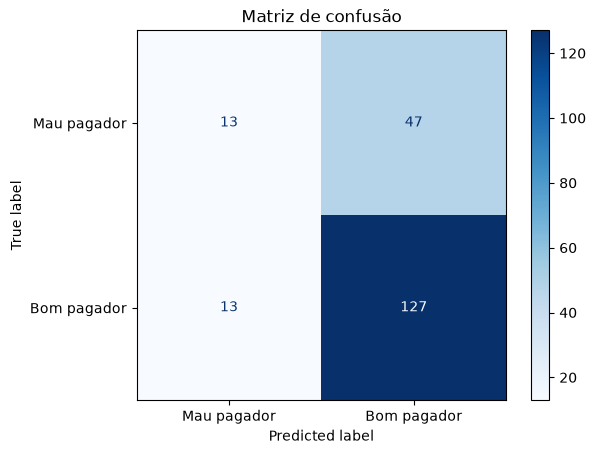

Acurácia:
0.7

Relatório de classificação:
              precision    recall  f1-score   support

 Mau pagador       0.50      0.22      0.30        60
 Bom pagador       0.73      0.91      0.81       140

    accuracy                           0.70       200
   macro avg       0.61      0.56      0.56       200
weighted avg       0.66      0.70      0.66       200



In [13]:
from sklearn.metrics import accuracy_score
y_pred = modelo_final.predict(X_test)
from sklearn.metrics import classification_report
matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=['bad', 'good']
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Mau pagador', 'Bom pagador']
)

disp.plot(cmap='Blues')
plt.title('Matriz de confusão')
plt.show()

print("Acurácia:")
print(accuracy_score(y_test, y_pred))

print("\nRelatório de classificação:")

print(
    classification_report(y_test,y_pred,labels=['bad', 'good'],target_names=['Mau pagador', 'Bom pagador']))

O erro mais frequente foi classificar um mau pagador como bom pagador. Isso ocorreu em 47 registros do conjunto de teste.
Esse tipo de erro é chamado de falso negativo em relação à classe bad. Em uma aplicação de análise de crédito, ele representa uma situação potencialmente arriscada, pois um cliente com características de mau pagador pode ser classificado como bom pagador e receber crédito, logo ele vai causar prejuízo já que ele não vai pagar.

Uma possibilidade para reduzir a quantidade de maus pagadores classificados incorretamente como bons pagadores é utilizar pesos diferentes para as classes durante o treinamento.

Nesse experimento, a classe bad recebe peso 2, enquanto a classe good recebe peso 1. Dessa forma, os erros relacionados à classificação dos maus pagadores passam a ter maior influência no treinamento da árvore.

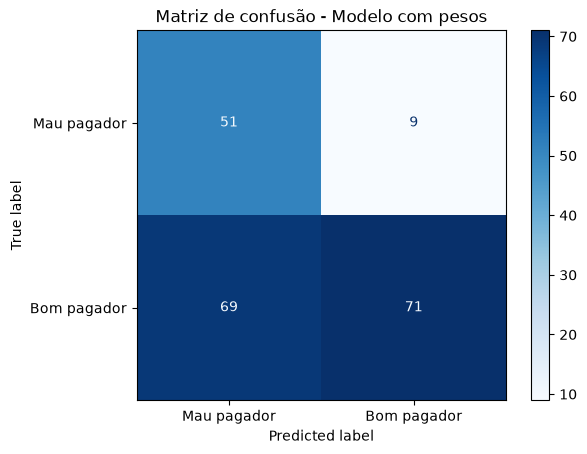

Acurácia:
0.61

Relatório de classificação:
              precision    recall  f1-score   support

 Mau pagador       0.42      0.85      0.57        60
 Bom pagador       0.89      0.51      0.65       140

    accuracy                           0.61       200
   macro avg       0.66      0.68      0.61       200
weighted avg       0.75      0.61      0.62       200



In [14]:
modelo_ponderado = tree.DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    class_weight={'bad': 2, 'good': 1},
    random_state=42
)

modelo_ponderado.fit(X_train, y_train)

y_pred_ponderado = modelo_ponderado.predict(X_test)

matriz_ponderada = confusion_matrix(
    y_test,
    y_pred_ponderado,
    labels=['bad', 'good']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_ponderada,
    display_labels=['Mau pagador', 'Bom pagador']
)

disp.plot(cmap='Blues')
plt.title('Matriz de confusão - Modelo com pesos')
plt.show()

print("Acurácia:")
print(accuracy_score(y_test, y_pred_ponderado))

print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred_ponderado,
        labels=['bad', 'good'],
        target_names=['Mau pagador', 'Bom pagador']
    )
)

O modelo com class_weight={'bad': 2, 'good': 1} apresentou acurácia de 61%, inferior aos 70% obtidos pelo modelo original. Entretanto, houve uma melhora expressiva na identificação dos maus pagadores: a revocação (recall) da classe bad aumentou de 22% para 85%.
Por outro lado, a revocação dos bons pagadores caiu de 91% para 51%. Isso demonstra que o aumento do peso da classe bad tornou o modelo mais sensível à identificação de clientes com risco de inadimplência, mas também aumentou a quantidade de bons pagadores classificados incorretamente como maus pagadores.